# LAB 09 · Thực nghiệm NER và Information Extraction

Mục 12–27 theo số của đề.


Nếu thiếu thư viện, chạy trong một cell:

```python
%pip install "transformers==4.49.0" "torch>=2.6,<3" scikit-learn pandas matplotlib
```

Lần đầu chạy, chương trình tải ba split CoNLL-2003. Nếu đã có dữ liệu, đặt biến
môi trường `LAB09_DATA_DIR` trỏ tới thư mục chứa eng.train, eng.testa và eng.testb.

Checkpoint đi kèm giúp chạy lại toàn bộ đánh giá mà không phải train thêm.
Để train từ đầu, đặt `os.environ["LAB09_RETRAIN"] = "1"` trước cell cấu hình.
Lần chạy đi kèm dùng **BERT Tiny** tiếng Anh, 2 tầng, hidden size 128, 6 epoch,
batch 48, LR 1.2e-4, seed 42 và Strategy A. Chọn epoch bằng entity F1 trên validation.
Hai mô hình dùng 14.041 câu train và cùng 3.453 câu test.

Nguồn dữ liệu và API. [CoNLL-2003](https://huggingface.co/datasets/eriktks/conll2003),
[split CoNLL dạng văn bản](https://github.com/synalp/NER/tree/master/corpus/CoNLL-2003),
[BERT Tiny](https://huggingface.co/google/bert_uncased_L-2_H-128_A-2),
[Hugging Face Token Classification](https://huggingface.co/docs/transformers/tasks/token_classification).

## 16. Core Implementation

`word_ids()` ánh xạ token về từ để gán nhãn ở mảnh đầu. Special tokens,
mảnh tiếp theo và padding nhận -100. Collator padding theo batch.
Code in tokens, input IDs, attention mask, word IDs, labels, logits và dự đoán.
Có kiểm tra truncation giữ đủ từ của mỗi câu ở cả ba split.

Các hàm pipeline nằm trong [ner_core.py](ner_core.py).

In [1]:
import json
import pandas as pd
from IPython.display import display

pd.set_option('display.max_colwidth', None)
import os
import random
from collections import Counter
from pathlib import Path

import numpy as np
import torch
from transformers import (
    AutoModelForTokenClassification,
    AutoTokenizer,
    DataCollatorForTokenClassification,
    get_linear_schedule_with_warmup,
)

from baseline_ner import (
    LABELS, SEED, TYPES, bio_spans, entity_set, load_corpus,
    predict_baseline, score_sequences, score_sets,
    train_baseline, write_csv,
)

from ner_core import IGNORE, encode_rows, epoch_batches, make_model, predict_words

ROOT = Path.cwd()
MODEL_ID = "google/bert_uncased_L-2_H-128_A-2"
MODEL_SOURCE = os.getenv("LAB09_MODEL_SOURCE", MODEL_ID)
MODEL_DIR = ROOT / "checkpoint"
RETRAIN = os.getenv("LAB09_RETRAIN", "0") == "1" or not (MODEL_DIR / "model.safetensors").is_file()
TOKENIZER_SOURCE = MODEL_SOURCE if RETRAIN else MODEL_DIR
MAX_LENGTH = 256
EPOCHS = 6
BATCH_SIZE = 48
LEARNING_RATE = 1.2e-4
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
print(f"Thiết bị: {DEVICE} · seed: {SEED} · checkpoint gốc: {MODEL_ID}")

corpus = load_corpus()
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_SOURCE, use_fast=True)
assert tokenizer.is_fast
print({split: len(rows) for split, rows in corpus.items()})

Thiết bị: cpu · seed: 42 · checkpoint gốc: google/bert_uncased_L-2_H-128_A-2
{'train': 14041, 'validation': 3250, 'test': 3453}


In [2]:
encoded = {
    split: [item for start in range(0, len(rows), 512)
            for item in encode_rows(rows[start:start + 512], tokenizer, MAX_LENGTH)]
    for split, rows in corpus.items()
}
collate = DataCollatorForTokenClassification(tokenizer, label_pad_token_id=IGNORE)
print("Độ dài input lớn nhất theo split:",
      {split: max(len(item["input_ids"]) for item in rows) for split, rows in encoded.items()})

Độ dài input lớn nhất theo split: {'train': 164, 'validation': 146, 'test': 140}


In [3]:
model = (make_model(MODEL_SOURCE, DEVICE) if RETRAIN else
         AutoModelForTokenClassification.from_pretrained(MODEL_DIR).to(DEVICE))
preview = collate(encoded["train"][:2])
with torch.inference_mode():
    model.eval()
    demo = model(**preview.to(DEVICE), output_hidden_states=True)
demo_ids = preview["input_ids"][0].cpu().tolist()
print("tokens:", tokenizer.convert_ids_to_tokens(demo_ids))
print("input_ids:", demo_ids)
print("attention_mask:", preview["attention_mask"][0].cpu().tolist())
demo_words = corpus["train"][0]["words"]
demo_word_ids = tokenizer(demo_words, is_split_into_words=True).word_ids()
print("word_ids (pad = None):", demo_word_ids + [None] * (len(demo_ids) - len(demo_word_ids)))
print("labels:", preview["labels"][0].cpu().tolist())
print("H:", tuple(demo.hidden_states[-1].shape), "logits:", tuple(demo.logits.shape))
print("logits của token đầu tiên có nhãn:", demo.logits[0, 1].cpu().tolist())
print("predictions của model đang nạp:", predict_words(model, encoded["train"][:1], collate, DEVICE, BATCH_SIZE)[0])
del demo, preview

tokens: ['[CLS]', 'eu', 'rejects', 'german', 'call', 'to', 'boycott', 'british', 'lamb', '.', '[SEP]']
input_ids: [101, 7327, 19164, 2446, 2655, 2000, 17757, 2329, 12559, 1012, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
word_ids (pad = None): [None, 0, 1, 2, 3, 4, 5, 6, 7, 8, None]
labels: [-100, 3, 0, 7, 0, 0, 0, 7, 0, 0, -100]
H: (2, 11, 128) logits: (2, 11, 9)
logits của token đầu tiên có nhãn: [0.011519558727741241, 1.1233689785003662, -2.707848310470581, 4.281841278076172, -1.8925230503082275, 0.32279953360557556, -2.669135570526123, 2.4539904594421387, -2.6034772396087646]
predictions của model đang nạp: ['B-ORG', 'O', 'B-MISC', 'O', 'O', 'O', 'B-MISC', 'O', 'O']


### 16.1. Fine-tune và chọn checkpoint theo validation entity F1

In [4]:
if RETRAIN:
    train_items = encoded["train"]
    validation_gold = [row["tags"] for row in corpus["validation"]]
    validation_entities = entity_set(validation_gold)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    total_steps = EPOCHS * len(epoch_batches(train_items, 0, BATCH_SIZE))
    scheduler = get_linear_schedule_with_warmup(optimizer, total_steps // 20, total_steps)
    use_bf16 = DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()
    history = []
    best_f1 = -1.0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_sum, seen_labels = 0.0, 0
        for indices in epoch_batches(train_items, epoch, BATCH_SIZE):
            batch = collate([train_items[i] for i in indices])
            n_labels = batch["labels"].ne(IGNORE).sum().item()
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.bfloat16, enabled=use_bf16):
                loss = model(**batch.to(DEVICE)).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            loss_sum += loss.item() * n_labels
            seen_labels += n_labels
        val_predictions = predict_words(model, encoded["validation"], collate, DEVICE, BATCH_SIZE)
        val = score_sets(validation_entities, entity_set(val_predictions))
        history.append({"epoch": epoch, "train_loss": loss_sum / seen_labels, "val_f1": val["f1"]})
        print(f"Epoch {epoch:>2}/{EPOCHS} | loss {loss_sum / seen_labels:.4f} | "
              f"validation entity F1 {val['f1']:.4f}", flush=True)
        if val["f1"] > best_f1:
            best_f1 = val["f1"]
            best_epoch = epoch
            model.save_pretrained(MODEL_DIR)
            tokenizer.save_pretrained(MODEL_DIR)


    record = {
        "model_id": MODEL_ID, "seed": SEED, "device": str(DEVICE),
        "epochs": EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
        "max_length": MAX_LENGTH, "best_epoch": best_epoch, "history": history,
        "torch": torch.__version__,
    }
    (MODEL_DIR / "training_history.json").write_text(json.dumps(record, indent=2) + "\n", encoding="utf-8")
else:
    record = json.loads((MODEL_DIR / "training_history.json").read_text(encoding="utf-8"))
    history, best_epoch = record["history"], record["best_epoch"]
    best_f1 = next(item["val_f1"] for item in history if item["epoch"] == best_epoch)
    for item in history:
        print(f"Epoch {item['epoch']:>2}/{record['epochs']} | loss {item['train_loss']:.4f} | "
              f"validation entity F1 {item['val_f1']:.4f}")
model = AutoModelForTokenClassification.from_pretrained(MODEL_DIR).to(DEVICE)
print(f"Chọn epoch {best_epoch}, validation entity F1 = {best_f1:.4f}")

Epoch  1/6 | loss 0.7095 | validation entity F1 0.5970
Epoch  2/6 | loss 0.2328 | validation entity F1 0.7544
Epoch  3/6 | loss 0.1653 | validation entity F1 0.7868
Epoch  4/6 | loss 0.1365 | validation entity F1 0.8015
Epoch  5/6 | loss 0.1212 | validation entity F1 0.8100
Epoch  6/6 | loss 0.1149 | validation entity F1 0.8118
Chọn epoch 6, validation entity F1 = 0.8118


In [5]:
test = corpus["test"]
gold = [row["tags"] for row in test]
transformer_predictions = predict_words(model, encoded["test"], collate, DEVICE, BATCH_SIZE)

## 17. Experiment 1 — Tokenization Analysis

Lấy mẫu bằng seed 42 trên **train** gồm 20 câu ngắn (≤10 từ) và 20 câu dài (≥25 từ).
**Words** là số từ gốc. **Subwords** bao gồm từ chỉ có một mảnh và bỏ token đặc biệt.
**Từ bị tách** đếm số từ có hơn một mảnh. **Pieces tăng thêm** bằng số mảnh trừ số từ.
Với một nhóm, $R=\sum \text{subwords}/\sum \text{words}$.
Từ entity gồm cả B và I. Bảng trình bày số liệu theo câu, độ dài câu,
entity/non-entity, type và dạng từ.

In [6]:
def tokenization_experiment(source, tokenizer, n_each=20):
    rng = random.Random(SEED)
    pools = {
        "Ngắn (≤10 từ)": [i for i, row in enumerate(source) if len(row["words"]) <= 10],
        "Dài (≥25 từ)": [i for i, row in enumerate(source) if len(row["words"]) >= 25],
    }
    sentences, word_rows = [], []
    for group, pool in pools.items():
        for row_id in sorted(rng.sample(pool, n_each)):
            row = source[row_id]
            encoding = tokenizer(row["words"], is_split_into_words=True, add_special_tokens=False)
            counts = Counter(encoding.word_ids())
            assert set(counts) == set(range(len(row["words"])))
            num_words = len(row["words"])
            num_pieces = len(encoding["input_ids"])
            num_split = sum(size > 1 for size in counts.values())
            sentences.append({
                "train_id": row_id + 1, "nhóm": group, "words": num_words,
                "subwords": num_pieces, "từ bị tách": num_split,
                "pieces tăng thêm": num_pieces - num_words, "R": num_pieces / num_words,
            })
            pieces_by_word = [[] for _ in row["words"]]
            for token, word_id in zip(encoding.tokens(), encoding.word_ids()):
                pieces_by_word[word_id].append(token)
            for i, (word, tag) in enumerate(zip(row["words"], row["tags"])):
                word_rows.append({
                    "train_id": row_id + 1, "word": word, "tag": tag,
                    "nhóm": "Non-entity" if tag == "O" else "Entity",
                    "entity_type": tag[2:] if tag != "O" else "O",
                    "subwords": counts[i], "bị tách": counts[i] > 1,
                    "pieces": " ".join(pieces_by_word[i]),
                    "dạng": ("có chữ số" if any(c.isdigit() for c in word)
                             else "có chữ viết hoa" if any(c.isupper() for c in word)
                             else "chữ thường" if word.isalpha() else "dấu / ký tự khác"),
                })
    return pd.DataFrame(sentences), pd.DataFrame(word_rows)


def summarize_words(frame, group):
    result = frame.groupby(group, sort=False).agg(
        words=("word", "size"), subwords=("subwords", "sum"), split_words=("bị tách", "sum")
    )
    result["R"] = result["subwords"] / result["words"]
    result["split_rate"] = result["split_words"] / result["words"]
    return result


sentences, per_word = tokenization_experiment(corpus["train"], tokenizer)
by_sentence = sentences.groupby("nhóm", sort=False).agg(
    sentences=("train_id", "size"), words=("words", "sum"),
    subwords=("subwords", "sum"), split_words=("từ bị tách", "sum"),
)
by_sentence["R"] = by_sentence["subwords"] / by_sentence["words"]
by_sentence["split_rate"] = by_sentence["split_words"] / by_sentence["words"]
length_groups = summarize_words(per_word, "nhóm")
word_types = summarize_words(per_word, "entity_type")
shapes = summarize_words(per_word, "dạng")
display(sentences.round(4), by_sentence.round(4), length_groups.round(4),
        word_types.round(4), shapes.round(4))
examples = (per_word[per_word["bị tách"]].sort_values("subwords", ascending=False)
            .drop_duplicates("word").groupby("nhóm", sort=False).head(6))
display(examples[["train_id", "word", "tag", "pieces", "subwords"]])

,train_id,nhóm,words,subwords,từ bị tách,pieces tăng thêm,R
0,422,Ngắn (≤10 từ),2,3,1,1,1.5000
1,490,Ngắn (≤10 từ),1,3,1,2,3.0000
2,520,Ngắn (≤10 từ),6,11,3,5,1.8333
3,1493,Ngắn (≤10 từ),8,12,2,4,1.5000
4,1640,Ngắn (≤10 từ),9,9,0,0,1.0000
5,1785,Ngắn (≤10 từ),4,4,0,0,1.0000
6,1916,Ngắn (≤10 từ),8,8,0,0,1.0000
7,2317,Ngắn (≤10 từ),3,4,1,1,1.3333
8,3563,Ngắn (≤10 từ),5,9,2,4,1.8000
9,3788,Ngắn (≤10 từ),2,6,1,4,3.0000


,sentences,words,subwords,split_words,R,split_rate
nhóm,,,,,,
Ngắn (≤10 từ),20,116,190,34,1.6379,0.2931
Dài (≥25 từ),20,605,709,64,1.1719,0.1058


,words,subwords,split_words,R,split_rate
nhóm,,,,,
Non-entity,604,705,52,1.1672,0.0861
Entity,117,194,46,1.6581,0.3932


,words,subwords,split_words,R,split_rate
entity_type,,,,,
O,604,705,52,1.1672,0.0861
ORG,41,63,12,1.5366,0.2927
MISC,16,17,1,1.0625,0.0625
PER,46,94,30,2.0435,0.6522
LOC,14,20,3,1.4286,0.2143


,words,subwords,split_words,R,split_rate
dạng,,,,,
có chữ viết hoa,153,235,49,1.5359,0.3203
chữ thường,417,434,14,1.0408,0.0336
có chữ số,48,107,22,2.2292,0.4583
dấu / ký tự khác,103,123,13,1.1942,0.1262


,train_id,word,tag,pieces,subwords
99,10852,10-0-59-1,O,10 - 0 - 59 - 1,7
104,10852,10-1-39-1,O,10 - 1 - 39 - 1,7
101,10852,10-0-42-0,O,10 - 0 - 42 - 0,7
115,13860,04/06/96,O,04 / 06 / 96,5
77,9319,1996-08-27,O,1996 - 08 - 27,5
47,3788,1996-08-24,O,1996 - 08 - 24,5
365,9086,Eletropaulo,B-ORG,el ##et ##rop ##au ##lo,5
155,610,Ferencvaros,B-ORG,fe ##ren ##c ##var ##os,5
42,3563,Mujtaba,I-PER,mu ##j ##ta ##ba,4
357,6190,Odnosum,I-PER,o ##d ##nos ##um,4


### 17.1. Những loại từ nào thường bị tách?

Trong 40 câu đã chọn, **39,3% từ entity** bị tách, so với **8,6% non-entity**.
Dạng chứa chữ số bị tách nhiều nhất (45,8%), tiếp theo là dạng có chữ hoa (32,0%).
Eletropaulo và Ferencvaros có 5 mảnh mỗi từ; ngày 04/06/96 cũng có 5 mảnh dù nhãn O.
Từ chỉ có chữ thường có tỷ lệ tách 3,4%. Chữ hoa ở đây mô tả từ CoNLL gốc,
vì WordPiece uncased chuẩn hóa trước khi tra vocab.

R của nhóm ngắn là 1,6379 và nhóm dài là 1,1719. Các kiểu từ như ngày
tháng, số liệu có dấu và tên riêng có thể kéo R lên trong một câu ngắn.
Kết quả so sánh mô tả hai nhóm được lấy mẫu theo seed 42.

In [7]:
for group, row in length_groups.iterrows():
    print(f"{group}: {int(row['split_words'])}/{int(row['words'])} từ bị tách "
          f"({row['split_rate']:.1%}), R = {row['R']:.4f}.")
for group, row in by_sentence.iterrows():
    print(f"{group}: R = {row['R']:.4f}; tỷ lệ tách = {row['split_rate']:.1%}.")
for form, row in shapes.sort_values("split_rate", ascending=False).iterrows():
    print(f"{form}: {int(row['split_words'])}/{int(row['words'])} từ bị tách "
          f"({row['split_rate']:.1%}).")

Non-entity: 52/604 từ bị tách (8.6%), R = 1.1672.
Entity: 46/117 từ bị tách (39.3%), R = 1.6581.
Ngắn (≤10 từ): R = 1.6379; tỷ lệ tách = 29.3%.
Dài (≥25 từ): R = 1.1719; tỷ lệ tách = 10.6%.
có chữ số: 22/48 từ bị tách (45.8%).
có chữ viết hoa: 49/153 từ bị tách (32.0%).
dấu / ký tự khác: 13/103 từ bị tách (12.6%).
chữ thường: 14/417 từ bị tách (3.4%).


## 18. Experiment 2 — Baseline vs Transformer

P/R/F1 chính dùng **micro exact-match theo thực thể**, cùng test set và cùng quy ước BIO.
Token accuracy dễ bị chi phối bởi nhãn O. Entity F1 buộc model nhận đúng cả biên và type.

In [8]:
baseline_model = train_baseline(corpus["train"])
baseline_predictions = predict_baseline(baseline_model, test)
models = {
    "Logistic Regression": baseline_predictions,
    "BERT Tiny fine-tuned": transformer_predictions,
}
metrics = []
for model_name, sequences in models.items():
    for level, scores in score_sequences(gold, sequences).items():
        metrics.append({
            "task": "NER", "split": "CoNLL-2003 test", "n_sentences": len(test),
            "model": model_name, "level": level, **scores,
        })

results = pd.DataFrame(metrics)
entity_comparison = results[results["level"].eq("entity_exact_micro")]
display(entity_comparison[["model", "precision", "recall", "f1", "tp", "fp", "fn"]].round(4))

,model,precision,recall,f1,tp,fp,fn
0,Logistic Regression,0.5799,0.6640,0.6191,3750,2717,1898
2,BERT Tiny fine-tuned,0.7601,0.7838,0.7718,4427,1397,1221


## 19. Experiment 3 — Entity-Level Evaluation

Gold **New York [LOC]**, predicted **New [LOC]**. Từ New có BIO đúng, nên
word-level F1 bỏ O là 2/3. Ở mức entity, TP=0, FP=1 và FN=1 vì thiếu York, nên F1=0.
Bảng dưới tính lại ví dụ này và đối chiếu hai cấp trên test.

## 20. Precision / Recall / F1

Khóa span là *(sentence_id, start_word, end_word_exclusive, type)*.
$TP=|G\cap P|$, $FP=|P-G|$, $FN=|G-P|$.
$P_r=TP/(TP+FP)$, $R=TP/(TP+FN)$, $F_1=2TP/(2TP+FP+FN)$.
Word-level micro F1 dùng khóa *(sentence_id, word_id, BIO tag)* và bỏ O.

**Trả lời Prediction 1.** Trong lần chạy đi kèm, entity F1 tăng từ **61,91%**
lên **77,18%**. Mức tăng phù hợp với dự đoán rằng context rộng và WordPiece hữu ích.
Hai pipeline khác nhau ở nhiều thành phần nên thí nghiệm chưa tách riêng tác động
của pretraining và kiến trúc.

In [9]:
gold_demo = [["B-LOC", "I-LOC"]]
pred_demo = [["B-LOC", "O"]]
display(pd.DataFrame(score_sequences(gold_demo, pred_demo)).T.round(4))
display(results[["model", "level", "precision", "recall", "f1"]].round(4))
before, after = entity_comparison["f1"].tolist()
print(f"Prediction 1: thay đổi entity F1 = {(after - before) * 100:+.2f} điểm phần trăm.")

Prediction 1: thay đổi entity F1 = +15.27 điểm phần trăm.


,tp,fp,fn,support,precision,recall,f1
entity_exact_micro,0.0,1.0,1.0,1.0,0.0,0.0,0.0000
word_bio_micro_no_o,1.0,0.0,1.0,2.0,1.0,0.5,0.6667


,model,level,precision,recall,f1
0,Logistic Regression,entity_exact_micro,0.5799,0.6640,0.6191
1,Logistic Regression,word_bio_micro_no_o,0.6747,0.6702,0.6725
2,BERT Tiny fine-tuned,entity_exact_micro,0.7601,0.7838,0.7718
3,BERT Tiny fine-tuned,word_bio_micro_no_o,0.8148,0.7983,0.8065


## 21. Experiment 4 — Entity Type Analysis

**Vì sao hiệu năng khác nhau theo type?** LOC và PER đạt khoảng 84% F1.
Tên người thường có mẫu họ/tên, còn địa điểm có tín hiệu từ giới từ và tên nước/thành phố.
ORG đạt 68,13% dù có 6.321 gold train. Tên đội thể thao hay trùng địa danh và tên tổ chức
có thể gồm từ thông dụng hoặc nhiều thành tố, làm cả biên và loại khó hơn.
MISC đạt 64,58%, vừa ít mẫu hơn vừa gộp các dạng như quốc tịch và tên giải.
Bảng nhầm loại bên dưới chỉ tính các dự đoán có đúng biên gold.

In [10]:
from collections import defaultdict

gold_entities = entity_set(gold)
entities_by_model = {name: entity_set(sequences) for name, sequences in models.items()}
bert_entities = entities_by_model["BERT Tiny fine-tuned"]
train_counts = Counter(entity for row in corpus["train"] for _, _, entity in bio_spans(row["tags"]))
def by_kind(spans, entity):
    return {span for span in spans if span[-1] == entity}

type_metrics = [
    {"model": model_name, "entity_type": entity, "train_entities": train_counts[entity],
     **score_sets(by_kind(gold_entities, entity), by_kind(guesses, entity))}
    for model_name, guesses in entities_by_model.items() for entity in TYPES
]
write_csv(ROOT / "entity_metrics.csv", type_metrics)
display(pd.DataFrame(type_metrics).round(4))

gold_by_sentence = defaultdict(list)
pred_by_sentence = defaultdict(list)
for span in sorted(gold_entities):
    gold_by_sentence[span[0]].append(span)
for span in sorted(bert_entities):
    pred_by_sentence[span[0]].append(span)
gold_by_offset = {span[:3]: span[-1] for span in gold_entities}
type_swaps = Counter(
    (gold_by_offset[span[:3]], span[-1])
    for span in bert_entities
    if span[:3] in gold_by_offset and gold_by_offset[span[:3]] != span[-1]
)
display(pd.DataFrame([
    {"gold_type": actual, "pred_type": guess, "count": count}
    for (actual, guess), count in type_swaps.most_common()
]))

,model,entity_type,train_entities,tp,fp,fn,support,precision,recall,f1
0,Logistic Regression,PER,6600,1159,881,458,1617,0.5681,0.7168,0.6339
1,Logistic Regression,ORG,6321,901,1045,760,1661,0.4630,0.5424,0.4996
2,Logistic Regression,LOC,7140,1227,460,441,1668,0.7273,0.7356,0.7314
3,Logistic Regression,MISC,3438,463,331,239,702,0.5831,0.6595,0.6190
4,BERT Tiny fine-tuned,PER,6600,1394,296,223,1617,0.8249,0.8621,0.8431
5,BERT Tiny fine-tuned,ORG,6321,1134,534,527,1661,0.6799,0.6827,0.6813
6,BERT Tiny fine-tuned,LOC,7140,1435,296,233,1668,0.8290,0.8603,0.8444
7,BERT Tiny fine-tuned,MISC,3438,464,271,238,702,0.6313,0.6610,0.6458


,gold_type,pred_type,count
0,LOC,ORG,77
1,ORG,LOC,68
2,ORG,PER,66
3,ORG,MISC,54
4,MISC,ORG,38
5,PER,ORG,36
6,LOC,PER,26
7,PER,LOC,26
8,LOC,MISC,23
9,MISC,LOC,23


## 22. Experiment 5 — Entity Length

Đếm độ dài theo từ CoNLL. Gold và prediction được xếp nhóm độc lập theo độ dài
của từng span, nên một span bị cắt có thể tạo FN trong nhóm dài và FP trong nhóm ngắn.

**Trả lời Prediction 2.** Run đi kèm cho F1 **75,81% → 83,12% → 62,23% → 37,89%**
ở nhóm 1, 2, 3 và 4+. Hai từ có F1 cao nhất. Nhóm 3 và 4+ giảm rõ, phù hợp
một phần với giả thuyết cụm dài dễ sai biên. Nhóm 4+ có 62 gold span.

,model,entity_length,tp,fp,fn,support,precision,recall,f1
0,Logistic Regression,1,2575,2408,999,3574,0.5168,0.7205,0.6018
1,Logistic Regression,2,1122,265,654,1776,0.8089,0.6318,0.7095
2,Logistic Regression,3,51,37,185,236,0.5795,0.2161,0.3148
3,Logistic Regression,4+,2,7,60,62,0.2222,0.0323,0.0563
4,BERT Tiny fine-tuned,1,2857,1106,717,3574,0.7209,0.7994,0.7581
5,BERT Tiny fine-tuned,2,1421,222,355,1776,0.8649,0.8001,0.8312
6,BERT Tiny fine-tuned,3,131,54,105,236,0.7081,0.5551,0.6223
7,BERT Tiny fine-tuned,4+,18,15,44,62,0.5455,0.2903,0.3789


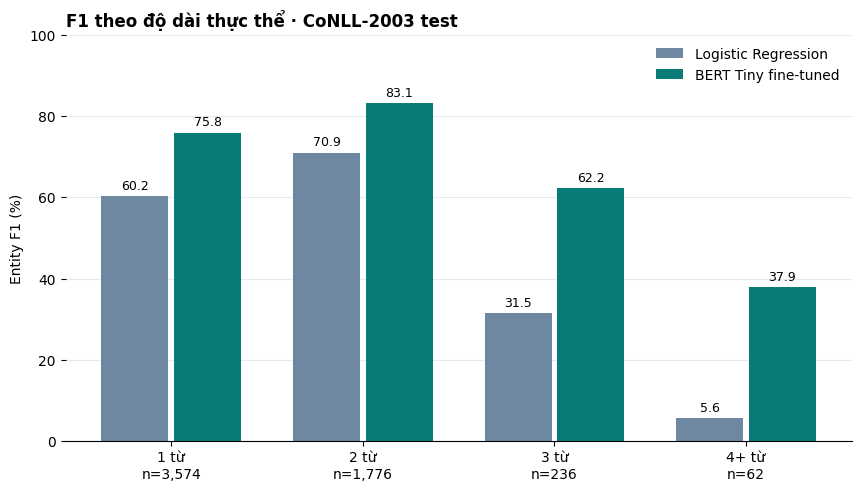

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

length_names = ("1", "2", "3", "4+")
def by_length(spans, bucket):
    return {span for span in spans if min(span[2] - span[1], 4) == bucket}

length_metrics = [
    {"model": model_name, "entity_length": name,
     **score_sets(by_length(gold_entities, bucket), by_length(guesses, bucket))}
    for model_name, guesses in entities_by_model.items()
    for bucket, name in enumerate(length_names, start=1)
]
length_frame = pd.DataFrame(length_metrics)
display(length_frame.round(4))
fig, ax = plt.subplots(figsize=(8.5, 4.8), layout="constrained")
ax.set_axisbelow(True)
ax.grid(axis="y", color="#DCE5EE", alpha=.8)
x = np.arange(len(length_names))
for offset, (name, group) in zip((-.19, .19), length_frame.groupby("model", sort=False)):
    color = "#6F88A2" if offset < 0 else "#087C78"
    bars = ax.bar(x + offset, group["f1"] * 100, width=.35, color=color, label=name)
    ax.bar_label(bars, fmt="%.1f", fontsize=9, padding=3)
support = length_frame[length_frame["model"].eq("BERT Tiny fine-tuned")]["support"]
ax.set_xticks(x, [f"{name} từ\nn={int(n):,}" for name, n in zip(length_names, support)])
ax.set_ylabel("Entity F1 (%)")
ax.set_title("F1 theo độ dài thực thể · CoNLL-2003 test", loc="left", weight="bold")
ax.set_ylim(0, 100)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(loc="upper right", frameon=False)
fig.savefig(ROOT / "entity_length_analysis.png", dpi=175, facecolor="white")
plt.show()

### 22.1. Confusion matrix nhãn BIO

Hàng gold, cột prediction, tính trên từ gốc và gồm nhãn O.
Mỗi ô có số lượng và tỷ lệ theo hàng. Trong run đi kèm, 22,0% từ I-ORG và
30,1% từ I-MISC chuyển thành O. Các lỗi bỏ vị trí bên trong cụm có thể
làm kỳ vọng exact match giảm rõ khi span dài.

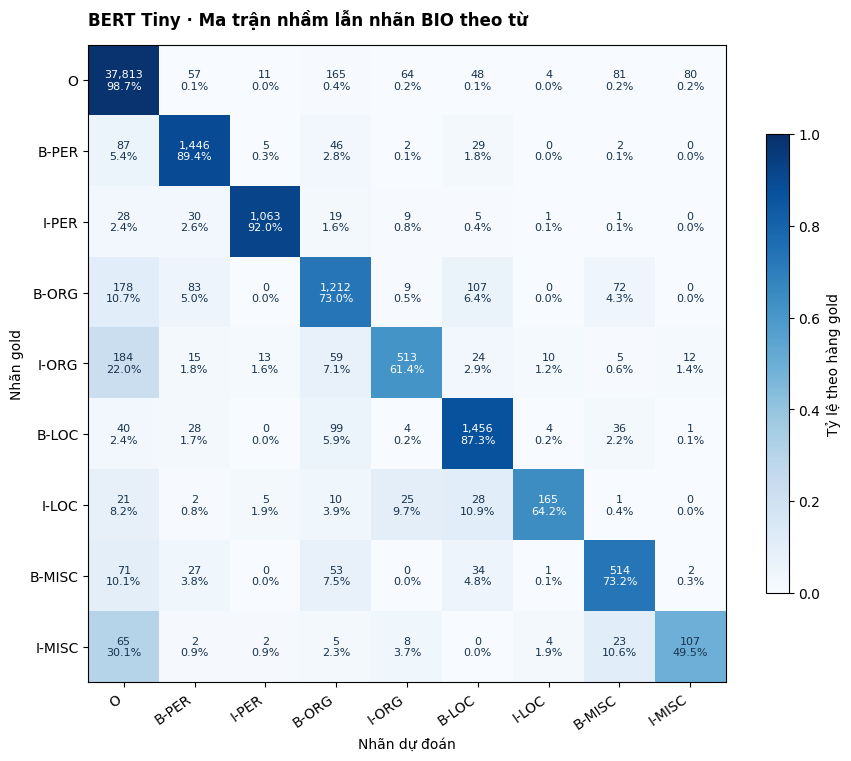

In [12]:
matrix = confusion_matrix(
    [tag for tags in gold for tag in tags],
    [tag for tags in transformer_predictions for tag in tags],
    labels=LABELS,
)
percent = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(9.3, 7.5), layout="constrained")
heat = ax.imshow(percent, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(LABELS)), LABELS, rotation=35, ha="right")
ax.set_yticks(range(len(LABELS)), LABELS)
ax.set(xlabel="Nhãn dự đoán", ylabel="Nhãn gold")
ax.set_title("BERT Tiny · Ma trận nhầm lẫn nhãn BIO theo từ", loc="left", weight="bold", pad=14)
for row, col in np.ndindex(matrix.shape):
    ax.text(col, row, f"{matrix[row, col]:,}\n{percent[row, col]:.1%}",
            ha="center", va="center", fontsize=8,
            color="white" if percent[row, col] >= .55 else "#18334D")
fig.colorbar(heat, ax=ax, shrink=.72, label="Tỷ lệ theo hàng gold")
fig.savefig(ROOT / "confusion_matrix.png", dpi=175, facecolor="white")
plt.show()

## 23. Experiment 6 — Error Analysis

**Trả lời Prediction 3.** So khớp surface theo casefold và theo type.
Run đi kèm cho recall khoảng 68,60% ở cả hai nhóm chưa gặp và gặp 1–2 lần,
so với 91,06% ở nhóm 3+. Kết quả ủng hộ lợi thế của entity quen thuộc.
Tần suất CoNLL train có thể đi cùng type, độ dài hoặc mức độ đa nghĩa.

Bảng chọn 5 FP tách rời, 5 FN tách rời, 5 lỗi boundary và 2 lỗi wrong type.
Gold và Prediction ghi span đang phân tích. O chỉ vùng không có thực thể ở phía tương ứng.

In [13]:
def surface(row, span):
    _, start, end, _ = span
    return " ".join(row["words"][start:end])


train_frequency = Counter(
    (kind, " ".join(row["words"][start:end]).casefold())
    for row in corpus["train"] for start, end, kind in bio_spans(row["tags"])
)
def train_seen(span):
    return train_frequency[span[-1], surface(test[span[0]], span).casefold()]


def frequency_group(n):
    return "0" if n == 0 else "1–2" if n <= 2 else "3+"


frequency_rows = []
for label in ("0", "1–2", "3+"):
    group_gold = {span for span in gold_entities if frequency_group(train_seen(span)) == label}
    for name, guessed in entities_by_model.items():
        correct = len(group_gold & guessed)
        frequency_rows.append({
            "model": name, "train_count": label, "gold": len(group_gold),
            "tp_exact": correct, "recall": correct / len(group_gold),
        })
frequency_frame = pd.DataFrame(frequency_rows)
display(frequency_frame.round(4))

,model,train_count,gold,tp_exact,recall
0,Logistic Regression,0,2618,1419,0.5420
1,BERT Tiny fine-tuned,0,2618,1796,0.6860
2,Logistic Regression,1–2,570,303,0.5316
3,BERT Tiny fine-tuned,1–2,570,391,0.6860
4,Logistic Regression,3+,2460,2028,0.8244
5,BERT Tiny fine-tuned,3+,2460,2240,0.9106


In [14]:
def overlaps(first, second):
    return first[0] == second[0] and max(first[1], second[1]) < min(first[2], second[2])


def select_span(spans, phrase):
    return next((span for span in spans if surface(test[span[0]], span) == phrase), None)


def matches_error(category, g, p, index):
    if category == "FP tách rời":
        return p is not None and not any(overlaps(p, span) for span in gold_by_sentence[index])
    if category == "FN tách rời":
        return g is not None and not any(overlaps(g, span) for span in pred_by_sentence[index])
    if g is None or p is None or g in bert_entities or p in gold_entities:
        return False
    if category == "Sai biên":
        return overlaps(g, p) and g[-1] == p[-1] and g[1:3] != p[1:3]
    return g[:3] == p[:3] and g[-1] != p[-1]


ERROR_CASES = [
    (45, "FP tách rời", None, "parrying",
     "Động từ phân từ chỉ động tác cản bóng. Câu có nhiều họ cầu thủ, nhưng từ này nằm sau dấu phẩy và theo sau bằng away."),
    (107, "FP tách rời", None, "b",
     "Ký hiệu b trong dòng điểm cricket chen giữa hai tên cầu thủ. Dạng dòng thiếu câu hoàn chỉnh làm dấu hiệu ngữ pháp yếu."),
    (153, "FP tách rời", None, "affray",
     "Trong charge of affray, từ chỉ hành vi bị truy tố. Cấu trúc at a court in London ở sau mới cung cấp địa điểm."),
    (193, "FP tách rời", None, "miss",
     "Từ đi ngay sau will, nên là động từ. Jason Little và Australia hai bên tạo các tên riêng lân cận có thể gây nhiễu."),
    (493, "FP tách rời", None, "PA",
     "PA nằm cùng W, L, T và PF trong hàng tiêu đề thống kê. Gold xem đây là một ký hiệu cột."),
    (16, "FN tách rời", "Bitar", None,
     "Chủ ngữ họ đơn lẻ đi với pulled off fine saves; không có tên đệm hoặc danh xưng. Gold surface/type chưa xuất hiện trong train."),
    (143, "FN tách rời", "BLINKER", None,
     "Tiêu đề SOCCER viết hoa toàn dòng, nên chữ hoa không giúp tách họ cầu thủ khỏi các từ khác. Bản uncased còn bỏ thông tin hoa/thường."),
    (194, "FN tách rời", "Little", None,
     "Little có dạng giống tính từ tiếng Anh. Cụm has opted và ngữ cảnh chấn thương ủng hộ cách đọc đây là họ người."),
    (219, "FN tách rời", "Champions ' League", None,
     "Tên giải có dấu nháy tách thành một từ gốc riêng. Model bỏ cả cụm MISC trong ngữ cảnh group; dấu nháy là trở ngại khả dĩ."),
    (561, "FN tách rời", "Rose Bowl", None,
     "Cụm a berth in the Rose Bowl chỉ giải/trận đấu. Surface/type này vắng trong train và hai thành phần đều là từ thông dụng."),
    (8, "Sai biên", "Soviet", "Soviet republic",
     "Model giữ đúng MISC nhưng ghép thêm danh từ chung republic sau tính từ Soviet."),
    (29, "Sai biên", "1995 World Cup", "World Cup",
     "Model nhận đúng lõi World Cup, bỏ năm 1995 mà gold gộp vào tên kỳ giải."),
    (117, "Sai biên", "B. Young", "Young",
     "Model bỏ chữ cái viết tắt B. ở đầu tên. B. là một từ CoNLL nhưng có nhiều mảnh WordPiece."),
    (145, "Sai biên", "Sheffield Wednesday", "Sheffield",
     "Wednesday thường là tên ngày. Trong trường hợp này nó là phần bắt buộc của tên câu lạc bộ."),
    (170, "Sai biên", "Teamsystem Bologna", "Bologna",
     "Hàng bảng điểm thiếu động từ; model giữ phần địa danh và bỏ Teamsystem là phần tên đội đã tách subword."),
    (20, "Sai loại", "FIFA", "FIFA",
     "Giữ đúng biên nhưng nhầm ORG sang MISC. Cụm ranked … by FIFA mô tả cơ quan xếp hạng, là dấu hiệu cho ORG."),
    (26, "Sai loại", "Murrayfield", "Murrayfield",
     "Model giữ biên nhưng gán PER. Giới từ at trong ngữ cảnh đá giao hữu là dấu hiệu tên sân/địa điểm."),
]

selected_errors = []
for test_id, category, gold_text, pred_text, explanation in ERROR_CASES:
    index = test_id - 1
    g = select_span(gold_by_sentence[index], gold_text)
    p = select_span(pred_by_sentence[index], pred_text)
    if matches_error(category, g, p, index):
        selected_errors.append((category, g, p, explanation))

# Một checkpoint được train lại có thể sai ở những câu khác.
counts = Counter(item[0] for item in selected_errors)
needs = {
    "FP tách rời": (5, "Span dự đoán không chồng bất kỳ span gold nào."),
    "FN tách rời": (5, "Không có span dự đoán chồng cụm gold."),
    "Sai biên": (5, "Span dự đoán và gold chung loại nhưng lệch biên từ."),
}
used_sentences = {(p if g is None else g)[0] for _, g, p, _ in selected_errors}
for index, row in enumerate(test):
    if all(counts[key] >= limit for key, (limit, _) in needs.items()):
        break
    if index in used_sentences or not 5 <= len(row["words"]) <= 30:
        continue
    gold_spans = gold_by_sentence[index]
    pred_spans = pred_by_sentence[index]
    candidates = [
        *(("FP tách rời", None, p) for p in pred_spans),
        *(("FN tách rời", g, None) for g in gold_spans),
        *(("Sai biên", g, p) for g in gold_spans for p in pred_spans),
    ]
    for category, g, p in candidates:
        limit, note = needs[category]
        if counts[category] < limit and matches_error(category, g, p, index):
            selected_errors.append((category, g, p, note))
            counts[category] += 1
            break

error_rows = []
for category, g, p, explanation in selected_errors:
    index = (p if g is None else g)[0]
    test_id = index + 1
    gold_text = surface(test[index], g) if g else None
    pred_text = surface(test[index], p) if p else None
    focus = p if g is None else g
    focus_words = test[index]["words"][focus[1]:focus[2]]
    pieces = " / ".join(" ".join(tokenizer.tokenize(word)) for word in focus_words)
    error_rows.append({
        "Test ID": test_id, "Text": " ".join(test[index]["words"]),
        "Gold": f"{gold_text} [{g[-1]}]" if g else "O ở vùng dự đoán",
        "Prediction": f"{pred_text} [{p[-1]}]" if p else "O ở vùng gold",
        "Error type": category,
        "Explanation": f"{explanation} WordPiece vùng phân tích: `{pieces}`."
                       + (f" Số lần surface/type trong train: {train_seen(g)}." if g else ""),
    })
error_frame = pd.DataFrame(error_rows)
display(error_frame)

,Test ID,Text,Gold,Prediction,Error type,Explanation
0,45,"Bitar saved well again from Miura in the 37th minute , parrying away his header from a corner .",O ở vùng dự đoán,parrying [PER],FP tách rời,"Động từ phân từ chỉ động tác cản bóng. Câu có nhiều họ cầu thủ, nhưng từ này nằm sau dấu phẩy và theo sau bằng away. WordPiece vùng phân tích: `parry ##ing`."
1,107,Saqlain Mushtaq b Harris 2,O ở vùng dự đoán,b [PER],FP tách rời,Ký hiệu b trong dòng điểm cricket chen giữa hai tên cầu thủ. Dạng dòng thiếu câu hoàn chỉnh làm dấu hiệu ngữ pháp yếu. WordPiece vùng phân tích: `b`.
2,153,"Bowyer , 19 , who was caught in the act by security cameras , pleaded guilty to a charge of affray at a court in London .",O ở vùng dự đoán,affray [LOC],FP tách rời,"Trong charge of affray, từ chỉ hành vi bị truy tố. Cấu trúc at a court in London ở sau mới cung cấp địa điểm. WordPiece vùng phân tích: `af ##fra ##y`."
3,193,Centre Jason Little will miss Australia 's end-of-tour fixture against the Barbarians at Twickenham on Saturday .,O ở vùng dự đoán,miss [ORG],FP tách rời,"Từ đi ngay sau will, nên là động từ. Jason Little và Australia hai bên tạo các tên riêng lân cận có thể gây nhiễu. WordPiece vùng phân tích: `miss`."
4,493,W L T PF PA,O ở vùng dự đoán,PA [ORG],FP tách rời,"PA nằm cùng W, L, T và PF trong hàng tiêu đề thống kê. Gold xem đây là một ký hiệu cột. WordPiece vùng phân tích: `pa`."
5,16,Bitar pulled off fine saves whenever they did .,Bitar [PER],O ở vùng gold,FN tách rời,Chủ ngữ họ đơn lẻ đi với pulled off fine saves; không có tên đệm hoặc danh xưng. Gold surface/type chưa xuất hiện trong train. WordPiece vùng phân tích: `bit ##ar`. Số lần surface/type trong train: 0.
6,143,SOCCER - BLINKER BAN LIFTED .,BLINKER [PER],O ở vùng gold,FN tách rời,"Tiêu đề SOCCER viết hoa toàn dòng, nên chữ hoa không giúp tách họ cầu thủ khỏi các từ khác. Bản uncased còn bỏ thông tin hoa/thường. WordPiece vùng phân tích: `blink ##er`. Số lần surface/type trong train: 0."
7,194,Little has opted not to risk aggravating the knee injury which ruled him out of a large chunk of the tour and is replaced by fellow Queenslander Daniel Herbert .,Little [PER],O ở vùng gold,FN tách rời,Little có dạng giống tính từ tiếng Anh. Cụm has opted và ngữ cảnh chấn thương ủng hộ cách đọc đây là họ người. WordPiece vùng phân tích: `little`. Số lần surface/type trong train: 1.
8,219,"League title-holders Steaua Bucharest , who finished bottom of their Champions ' League group in the European Cup , have only two players in the squad .",Champions ' League [MISC],O ở vùng gold,FN tách rời,Tên giải có dấu nháy tách thành một từ gốc riêng. Model bỏ cả cụm MISC trong ngữ cảnh group; dấu nháy là trở ngại khả dĩ. WordPiece vùng phân tích: `champions / ' / league`. Số lần surface/type trong train: 0.
9,561,"Pace , a junior , helped Ohio State to a 10-1 record and a berth in the Rose Bowl against Arizona State .",Rose Bowl [MISC],O ở vùng gold,FN tách rời,Cụm a berth in the Rose Bowl chỉ giải/trận đấu. Surface/type này vắng trong train và hai thành phần đều là từ thông dụng. WordPiece vùng phân tích: `rose / bowl`. Số lần surface/type trong train: 0.


## 24. Context Analysis

Bốn cặp từ **test set** giữ nguyên surface và chữ hoa/thường, mỗi cặp có hai loại gold.
Cột dự đoán báo các span chồng vùng được đánh dấu. Barcelona có một ca Transformer
nhầm; Hartford có một ca Transformer xử lý đúng trong khi baseline nhầm.

**Vì sao contextual representation hữu ích?** Static embedding ở LAB03
cung cấp cùng vector cho cùng mục từ. Self-attention ở LAB08 tạo hidden state phụ thuộc
những từ xuất hiện cùng câu. LAB09 dùng token head trên từng hidden state để chọn BIO.
Giới từ chỉ nơi chốn, bảng tỉ số và thông tin tuổi/gia đình có thể đổi loại của cùng tên.
Baseline có đặc trưng ±1 từ nên cũng xử lý được một số trường hợp.

In [15]:
CONTEXT_PAIRS = [
    ("Barcelona", (147, 180),
     "meeting in đánh dấu thành phố; tìm tên đội ở đầu dòng bảng điểm có (Spain) và dãy điểm. "
     "BERT nhầm câu 147 sang ORG trong khi baseline nhận đúng LOC."),
    ("Charlton", (3093, 3446),
     "Tỉ số giữa Charlton và Swindon chỉ đội; tuổi và his wife trong câu 3446 chỉ người. "
     "Xét lần nhắc đầu tiên ở câu 3446."),
    ("Hartford", (410, 1631),
     "Hàng tỉ số với Boston gợi đội; dấu phẩy và viết tắt bang Conn. gợi thành phố. "
     "BERT dự đoán đúng LOC ở 1631, baseline gán PER."),
    ("Toronto", (2319, 3374),
     "held both in … and in … gợi nơi đàm phán; tỉ số cạnh NY Rangers gợi đội thể thao."),
]
baseline_by_sentence = defaultdict(list)
for span in sorted(entities_by_model["Logistic Regression"]):
    baseline_by_sentence[span[0]].append(span)


def local_context(span, limit=8):
    index, start, end, _ = span
    words = test[index]["words"]
    return " ".join([
        *(["…"] if start > limit else []),
        *words[max(0, start - limit):start], f"⟦{' '.join(words[start:end])}⟧",
        *words[end:end + limit], *(["…"] if end + limit < len(words) else []),
    ])


def prediction_at(span, sentence_preds):
    candidates = [item for item in sentence_preds[span[0]] if overlaps(span, item)]
    return "; ".join(f"{surface(test[item[0]], item)} [{item[-1]}]" for item in candidates) or "O"


context_rows = []
for name, ids, cue in CONTEXT_PAIRS:
    types = set()
    for test_id in ids:
        index = test_id - 1
        target = next(span for span in gold_by_sentence[index] if surface(test[index], span) == name)
        types.add(target[-1])
        context_rows.append({
            "Surface": name, "Test ID": test_id, "Text quanh thực thể": local_context(target),
            "Gold": target[-1], "Baseline": prediction_at(target, baseline_by_sentence),
            "Transformer": prediction_at(target, pred_by_sentence), "Giải thích cặp": cue,
        })
    assert len(types) == 2
context_frame = pd.DataFrame(context_rows)
display(context_frame)

,Surface,Test ID,Text quanh thực thể,Gold,Baseline,Transformer,Giải thích cặp
0,Barcelona,147,"… 's players ' status committee , meeting in ⟦Barcelona⟧ , decided that although the Udinese document was …",LOC,Barcelona [LOC],Barcelona [ORG],meeting in đánh dấu thành phố; tìm tên đội ở đầu dòng bảng điểm có (Spain) và dãy điểm. BERT nhầm câu 147 sang ORG trong khi baseline nhận đúng LOC.
1,Barcelona,180,⟦Barcelona⟧ ( Spain ) 9 4 5 13,ORG,Barcelona [ORG],Barcelona [ORG],meeting in đánh dấu thành phố; tìm tên đội ở đầu dòng bảng điểm có (Spain) và dãy điểm. BERT nhầm câu 147 sang ORG trong khi baseline nhận đúng LOC.
2,Charlton,3093,⟦Charlton⟧ 2 Swindon 0,ORG,Charlton [ORG],Charlton [ORG],Tỉ số giữa Charlton và Swindon chỉ đội; tuổi và his wife trong câu 3446 chỉ người. Xét lần nhắc đầu tiên ở câu 3446.
3,Charlton,3446,"⟦Charlton⟧ , 61 , and his wife , Peggy …",PER,Charlton [PER],Charlton [PER],Tỉ số giữa Charlton và Swindon chỉ đội; tuổi và his wife trong câu 3446 chỉ người. Xét lần nhắc đầu tiên ở câu 3446.
4,Hartford,410,⟦Hartford⟧ 4 BOSTON 2,ORG,Hartford [ORG],Hartford [ORG],"Hàng tỉ số với Boston gợi đội; dấu phẩy và viết tắt bang Conn. gợi thành phố. BERT dự đoán đúng LOC ở 1631, baseline gán PER."
5,Hartford,1631,"BALANCE - ⟦Hartford⟧ , Conn .",LOC,Hartford [PER],Hartford [LOC],"Hàng tỉ số với Boston gợi đội; dấu phẩy và viết tắt bang Conn. gợi thành phố. BERT dự đoán đúng LOC ở 1631, baseline gán PER."
6,Toronto,2319,""" The negotiations will be held both in ⟦Toronto⟧ and in Jakarta , "" one source , …",LOC,Toronto [LOC],Toronto [LOC],held both in … and in … gợi nơi đàm phán; tỉ số cạnh NY Rangers gợi đội thể thao.
7,Toronto,3374,NY RANGERS 6 ⟦Toronto⟧ 5,ORG,Toronto [ORG],Toronto [ORG],held both in … and in … gợi nơi đàm phán; tỉ số cạnh NY Rangers gợi đội thể thao.


## 25. Application — Information Extraction

**Raw text → tách từ và WordPiece → NER Strategy A → giải BIO → span ký tự → JSON theo loại.**

`information_extraction.py` nạp checkpoint fine-tuned, giữ offset ký tự gốc và
dùng cửa sổ chồng lấn cho đầu vào dài. Ví dụ dưới là dự đoán chạy thực tế.
Có thể gọi từ terminal bằng
`python information_extraction.py --text "Anita Rao joined the World Bank in Washington."`.

In [16]:
import json
from information_extraction import NEWS_GOLD, NewsExtractor, evaluate

extractor = NewsExtractor(MODEL_DIR, device=DEVICE)
text = NEWS_GOLD[2][0]
print(text)
print(json.dumps(extractor.structured(text), indent=2, ensure_ascii=False))
display(pd.DataFrame(extractor.extract(text)))

Anita Rao joined the World Bank in Washington.
{
  "PERSON": [
    "Anita Rao"
  ],
  "ORG": [
    "World Bank"
  ],
  "LOCATION": [
    "Washington"
  ]
}


,text,type,start,end
0,Anita Rao,PERSON,0,9
1,World Bank,ORG,21,31
2,Washington,LOCATION,35,45


## 26. Mini Information Extraction Task

**Option A — News.** Ánh xạ PER → PERSON, ORG → ORG, LOC → LOCATION.
Gold gồm 30 câu news mô phỏng tiếng Anh được tạo và gán theo span trong NEWS_GOLD,
ngoài dữ liệu CoNLL. Tập có câu âm, tên nhiều từ và surface lặp với nhiều loại.
MISC nằm ngoài phạm vi ứng dụng.

## 27. Evaluation của Information Extraction

TP cần khớp câu, đầu/cuối ký tự và loại. Tính P/R/F1 micro và từng nhãn trên 30 câu.
Run đi kèm có **47 TP, 20 FP, 17 FN**, tức Precision 70,15%, Recall 73,44% và F1 71,76%.
ORG yếu nhất. Câu 2 dự đoán thừa **center [ORG]**. Câu 1 dự đoán biên
**Barack [PERSON]** ngắn hơn gold. Điểm số mô tả tập News mô phỏng này.

In [17]:
news_scores, news_details = evaluate(extractor)
display(pd.DataFrame(news_scores).round(4))
display(pd.DataFrame(news_details))
news_micro = news_scores[0]
metrics.append({
    "task": "IE", "split": "News gold mô phỏng", "n_sentences": len(news_details),
    "model": "BERT Tiny fine-tuned", "level": "entity_exact_micro",
    **{key: value for key, value in news_micro.items() if key != "entity_type"},
})
write_csv(ROOT / "results.csv", metrics)
print(f"{len(news_details)} câu; {sum(row['exact'] for row in news_details)} câu có toàn bộ span khớp.")
print("Đã ghi results.csv, entity_metrics.csv, entity_length_analysis.png, "
      "confusion_matrix.png.")

30 câu; 15 câu có toàn bộ span khớp.
Đã ghi results.csv, entity_metrics.csv, entity_length_analysis.png, confusion_matrix.png.


,entity_type,tp,fp,fn,support,precision,recall,f1
0,MICRO,47,20,17,64,0.7015,0.7344,0.7176
1,PERSON,11,3,3,14,0.7857,0.7857,0.7857
2,ORG,16,13,6,22,0.5517,0.7273,0.6275
3,LOCATION,20,4,8,28,0.8333,0.7143,0.7692


,sentence_id,text,gold,prediction,exact
0,1,Barack Obama visited Paris after meeting officials from UNESCO.,"[Barack Obama [PERSON], Paris [LOCATION], UNESCO [ORG]]","[Barack [PERSON], Paris [LOCATION]]",False
1,2,Microsoft opened a research center in Dublin.,"[Microsoft [ORG], Dublin [LOCATION]]","[Microsoft [ORG], center [ORG], Dublin [LOCATION]]",False
2,3,Anita Rao joined the World Bank in Washington.,"[Anita Rao [PERSON], World Bank [ORG], Washington [LOCATION]]","[Anita Rao [PERSON], World Bank [ORG], Washington [LOCATION]]",True
3,4,Reuters reporter Maria Chen arrived in Brussels on Monday.,"[Reuters [ORG], Maria Chen [PERSON], Brussels [LOCATION]]","[Reuters [ORG], Maria Chen [PERSON], Brussels [LOCATION]]",True
4,5,The United Nations Security Council met in New York.,"[United Nations Security Council [ORG], New York [LOCATION]]","[The [ORG], United Nations Security Council [ORG], New York [LOCATION]]",False
5,6,Barcelona defeated Valencia before returning to Barcelona for training.,"[Barcelona [ORG], Valencia [ORG], Barcelona [LOCATION]]","[Barcelona [ORG], Valencia [ORG], Barcelona [ORG]]",False
6,7,Cambridge University Press announced a partnership in Cambridge.,"[Cambridge University Press [ORG], Cambridge [LOCATION]]","[Cambridge University Press [ORG], Cambridge [ORG]]",False
7,8,Priya Desai addressed the audience in Nairobi.,"[Priya Desai [PERSON], Nairobi [LOCATION]]","[Priya [PERSON], Desai [ORG], Nairobi [LOCATION]]",False
8,9,Toyota and Panasonic announced a joint project in Osaka.,"[Toyota [ORG], Panasonic [ORG], Osaka [LOCATION]]","[Panasonic [ORG], Osaka [LOCATION]]",False
9,10,Daniel Kim met Sarah Patel in San Francisco.,"[Daniel Kim [PERSON], Sarah Patel [PERSON], San Francisco [LOCATION]]","[Daniel Kim [PERSON], Sarah Patel [PERSON], San Francisco [LOCATION]]",True


| File | Mục |
| --- | --- |
| baseline_ner.py | §3, §5, §13, §18–20 |
| tokenizer_alignment.ipynb | §8–11, §17 |
| prediction.md | §12 |
| calculations.md | §15 |
| ner_core.py | §16 |
| ner_finetuning.ipynb | §13–14, §16–27 |
| results.csv | §18–20, §27 |
| entity_metrics.csv | §21 |
| entity_length_analysis.png, confusion_matrix.png | §22 |
| error_analysis.md | §21–24 |
| information_extraction.py | §25–27 |